# Прогнозирование стоимости недвижимости в Калифорнии с помощью линейной регрессии

## 📌 Описание проекта
Это мой первый пет-проект в области машинного обучения и моя первая обученная модель! 
В качестве учебной задачи я исследую классический набор данных **California Housing** (на основе переписи населения 1990 года). Цель работы: построить и оптимизировать модель **линейной регрессии** для предсказания стоимости жилья в микрорайонах Калифорнии на основе социально-экономических и географических данных.

### Основные этапы работы:
1. Загрузка данных и первичный анализ (EDA).
2. Очистка данных от аномалий (выбросов) и борьба с мультиколлинеарностью.
3. Конструирование новых географических признаков (Feature Engineering).
4. Обучение модели и оценка её качества с помощью бизнес-метрик ($R^2$, MAE, RMSE).
5. Визуальный анализ ошибок (остатков) модели.


In [1]:
# 1. Импорт базовых библиотек для работы с данными и визуализации
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Импорт встроенного датасета и инструментов машинного обучения
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 3. Импорт инструмента для расчёта географических расстояний
from scipy.spatial.distance import cdist

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

## 1. Загрузка и первичный анализ данных

In [3]:
# Загрузка датасета и перевод его в формат Pandas DataFrame
california_dataset = fetch_california_housing()
data = pd.DataFrame(data=california_dataset.data, columns=california_dataset.feature_names)
data["Price"] = california_dataset.target

# Выведем базовую статистику по всем признакам
data.describe()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 2. Визуализация данных


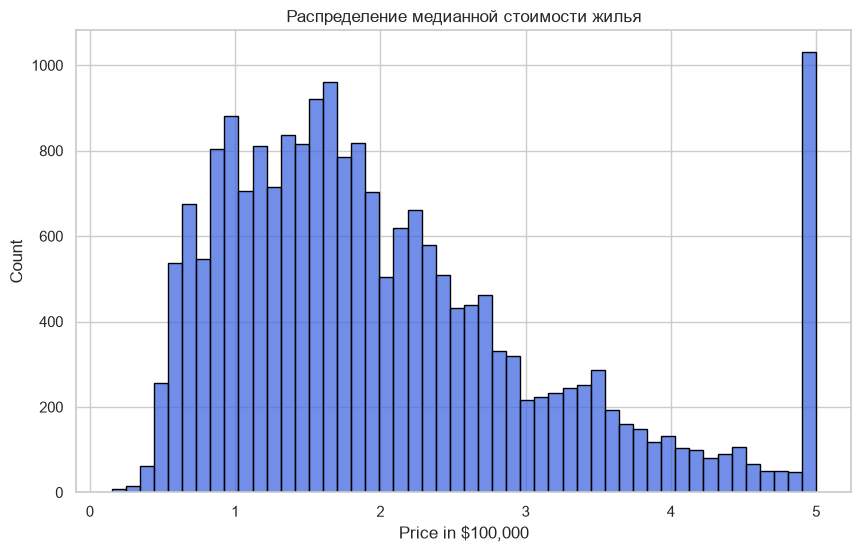

In [4]:
# График 1: Распределение целевой переменной (Цены)
plt.figure(figsize=(10, 6))
sns.histplot(data["Price"], ec="black", color="royalblue", bins=50)
plt.xlabel("Price in $100,000")
plt.ylabel("Count")
plt.title("Распределение медианной стоимости жилья")
plt.show()


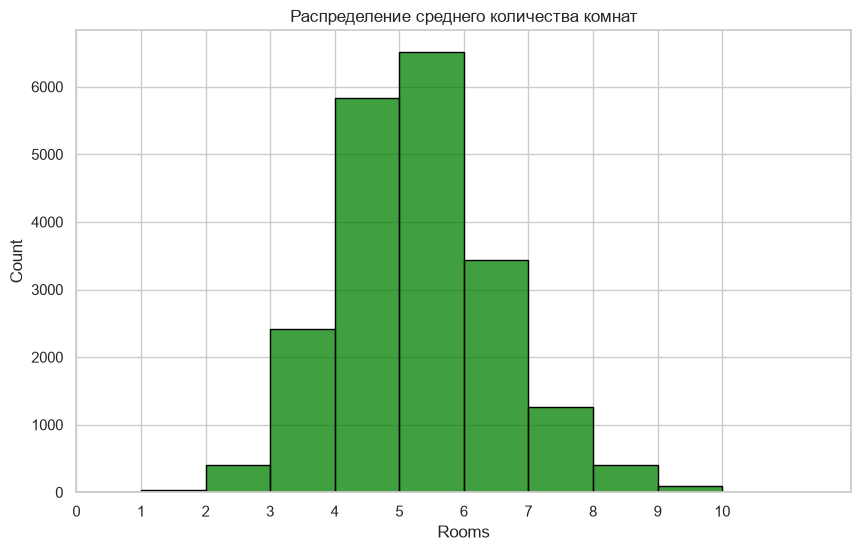

In [5]:
# График 2: Распределение среднего количества комнат (с шагом 1 и ограничением оси)
plt.figure(figsize=(10, 6))
plt.xlim(0, 12)
plt.xticks(np.arange(0, 11, 1))
plt.xlabel("Rooms")
plt.ylabel("Count")
plt.title("Распределение среднего количества комнат")
sns.histplot(data["AveRooms"], ec="black", color="green", bins=10, binrange=(0, 10))
plt.show()


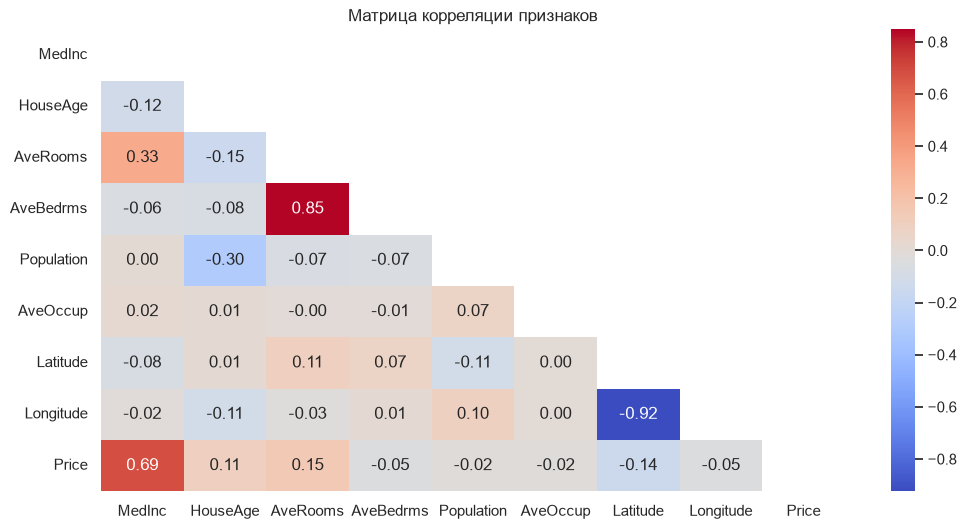

In [6]:
# График 3: Тепловая карта корреляции признаков (с маской)
plt.figure(figsize=(12, 6))
sns.set_style("white")

# Создаем маску для скрытия дублирующегося верхнего треугольника матрицы
mask = np.zeros_like(data.corr())
triangle_indices = np.triu_indices_from(mask)
mask[triangle_indices] = True

sns.heatmap(data.corr(), annot=True, mask=mask, cmap="coolwarm", fmt=".2f")
plt.title("Матрица корреляции признаков")
plt.show()


### 📊 Выводы на основе визуализации и анализа данных:
1. **Искусственное ограничение цены (Censoring):** На гистограмме цен виден огромный изолированный столбик на отметке `5.0`. Дома дороже этой суммы были округлены при сборе данных. Эту "полку" нужно удалить, чтобы не искажать предсказания линейной модели.
2. **Аномальные выбросы:** На графике распределения комнат виден длинный «хвост» выбросов, уходящий в пустоту. Статистика `data.describe()` подтверждает это: максимум по комнатам равен 141, а по числу жильцов (`AveOccup`) - 1243. Такие аномалии сильно ломают линейную регрессию.
3. **Мультиколлинеарность:** На тепловой карте видно, что признаки `AveRooms` и `AveBedrms` имеют критически высокую корреляцию (0.85). Один из них (`AveBedrms`) мы удалим, иначе веса модели станут нестабильными.
4. **Географические координаты:** Линейная регрессия плохо справляется с широтой (`Latitude`) и долготой (`Longitude`) по отдельности, хотя они сильно скоррелированы между собой (-0.92). Заменим их на евклидово расстояние до двух главных экономических центров: **Сан-Франциско (SF)** и **Лос-Анджелеса (LA)**.


## 3. Очистка данных и Инженерия признаков (Feature Engineering)


In [8]:
# 1. Фильтруем данные от искусственного ограничения цены
data_clean = data[data["Price"] < 5.0]

# 2. Фильтруем экстремальные выбросы по комнатам, населению и числу жильцов
data_clean = data_clean[data_clean["AveRooms"] < 10]
data_clean = data_clean[data_clean["Population"] < 15000]
data_clean = data_clean[data_clean["AveOccup"] < 10]

In [9]:
# 3. Расчёт расстояний до Сан-Франциско и Лос-Анджелеса
coords = data_clean[['Latitude', 'Longitude']].values
sf_coord = [[37.7749, -122.4194]]  # Координаты СФ
la_coord = [[34.0522, -118.2437]]  # Координаты ЛА

data_clean['Dist_to_SF'] = cdist(coords, sf_coord, metric='euclidean')
data_clean['Dist_to_LA'] = cdist(coords, la_coord, metric='euclidean')


In [11]:
prices = data_clean["Price"]
features = data_clean.drop(["Price", "AveBedrms", "Latitude", "Longitude"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(features, prices, test_size=0.2, random_state=12)


## 4. Обучение модели Линейной Регрессии


In [12]:
regr = LinearRegression()
regr.fit(X_train, y_train)

# Вывод коэффициентов детерминации R²
print('Training data R-squared:', regr.score(X_train, y_train))
print('Test data R-squared:', regr.score(X_test, y_test))
print('Intercept:', regr.intercept_)

# Посмотрим на веса (коэффициенты) перед каждым признаком
pd.DataFrame(data=regr.coef_, index=X_train.columns, columns=['coef'])


Training data R-squared: 0.558693519905864
Test data R-squared: 0.5755150801786886
Intercept: 2.179647782118042


,coef
MedInc,0.466214
HouseAge,0.011790
AveRooms,-0.138648
Population,0.000047
AveOccup,-0.311353
Dist_to_SF,-0.100927
Dist_to_LA,-0.127488


## 5. Оценка качества модели и бизнес-метрики (перевод ошибок в $)


In [13]:
# Делаем предсказание на тестовой выборке
y_pred = regr.predict(X_test)

# Считаем средние ошибки
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Так как целевая переменная выражена в сотнях тысяч долларов, умножаем на 100 000
print(f"Средняя абсолютная ошибка (MAE): ${mae * 100000:,.2f}")
print(f"Среднеквадратичная ошибка (RMSE): ${rmse * 100000:,.2f}")


Средняя абсолютная ошибка (MAE): $47,296.67
Среднеквадратичная ошибка (RMSE): $62,598.04


## 6. Анализ остатков (ошибок) модели


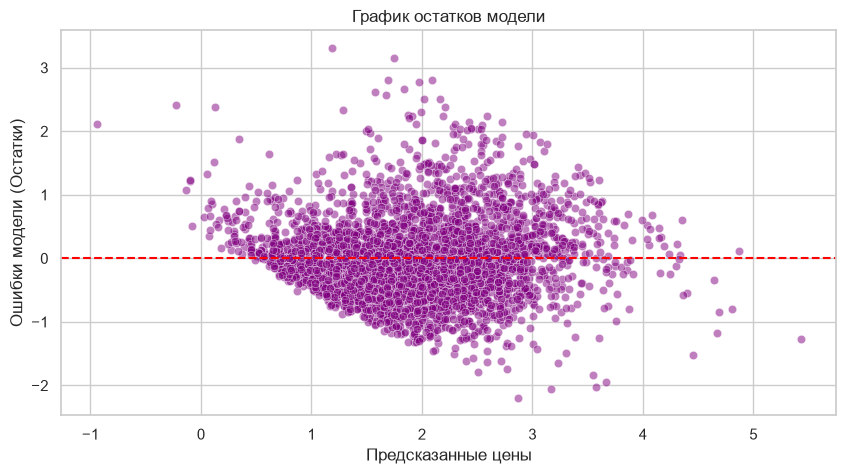

In [14]:
# Расчёт остатков (разница между реальной ценой и предсказанной)
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
# Строим график разброса ошибок
sns.scatterplot(x=y_pred, y=residuals, color="purple", alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Предсказанные цены')
plt.ylabel('Ошибки модели (Остатки)')
plt.title('График остатков модели')
plt.show()


## 7. Итоговые аналитические выводы

### 📈 Оценка качества модели:
* Модель демонстрирует стабильный коэффициент детерминации **R² ≈ 0.559 на обучении и ≈ 0.575 на тесте**. Отсутствие разрыва между метриками доказывает, что модель **не переобучена** и будет хорошо работать на новых данных.
* **MAE = \$47,296.67** означает, что в среднем наш первый алгоритм ошибается всего на ~47 тысяч долларов при оценке рыночной стоимости объекта. Для простой линейной регрессии на таком зашумленном датасете это отличный показатель.
* График остатков демонстрирует равномерное распределение ошибок вокруг нуля в виде хаотичного облака (выполняется важное свойство *гомоскедастичности*), что подтверждает правильность очистки данных.

### 🔍 Интерпретация весов (коэффициентов) модели:
* **Медианный доход (`MedInc` = 0.466):** Оказался самым сильным признаком. При росте дохода жителей района на 1 единицу (10 000\$), базовая стоимость жилья вырастает примерно на **46 620\$**. Более обеспеченные районы стоят значительно дороже.
* **Географический фактор (`Dist_to_LA` = -0.127 & `Dist_to_SF` = -0.100):** Наша географическая инженерия признаков сработала идеально. Коэффициенты получились отрицательными: при удалении от Лос-Анджелеса на 1 условную единицу цена падает на **12 740\$**, а при удалении от Сан-Франциско - на **10 090\$**.
* **Плотность населения (`AveOccup` = -0.311):** Чем больше в среднем людей живет в одном доме, тем ниже цена. Модель уловила, что перенаселенные кварталы оцениваются рынком ниже.
* **Количество комнат (`AveRooms` = -0.138):** Отрицательный знак обусловлен спецификой Калифорнии: огромные многокомнатные дома чаще строятся в дешевых внутренних (сельских) частях штата, где земля дешевле, в то время как на дорогих побережья преобладает более компактное жилье.
